# Flux attribution: which linear error drives the quasilinear flux error? (Fusion_PhD-qp5.52, WP2)

For every code arm on GS2's exact $(k_y,\beta)$ grid, the MG saturation rule (`giacomin_quasi-linear_2025`) in
pyrokinetics is applied to the code's linear solution and to GS2's. Its linear inputs (`SaturationRules.mg_ingredients`)
are, per $k_y$, $\beta$ and field $f$:
- $\gamma$, the growth rate (zero where stable or, for GS2, not converged);
- $A_f=\sqrt{\max|f|^2/\max|\phi|^2}$, the field amplitude ratios (this is where $A_\parallel/\phi$ enters);
- $E_f=\langle|f|^2\rangle/\langle k_\perp^2|f|^2\rangle$, the eigenfunction extent.

$$\Lambda_k=\gamma_k\sum_f A_fE_f,\qquad \Lambda=\int\Lambda_k\,dk_y,\qquad Q=Q_0\Lambda^{\alpha}\quad(Q_0=25,\ \alpha=2.5).$$

The total heat flux does not depend on the QL weights: they only split $Q$ between species (checked below on GS2).
The code arms' `pyroscan.nc` store no fluxes, so their QL weights cannot be swapped; this notebook attributes the
**total** heat flux.

**Swaps.** Each ingredient of the code arm is replaced by GS2's, alone and in every combination, and
$\ln(Q_{\rm code}/Q_{\rm GS2})$ is split into Shapley shares of $\gamma$, $A$ and $E$:
$$\phi_i=\sum_{S\subseteq N\setminus\{i\}}\frac{|S|!\,(n-|S|-1)!}{n!}\big[v(S)-v(S\cup\{i\})\big],\qquad v(S)=\ln Q(\text{GS2's }S,\ \text{code's rest}).$$
The shares sum to $\ln(Q_{\rm code}/Q_{\rm GS2})$ exactly (asserted). Per $k_y$ the split is exact without Shapley for
$\gamma$: $\ln(\Lambda_k^{\rm code}/\Lambda_k^{\rm GS2})=\ln(\gamma^{\rm code}/\gamma^{\rm GS2})+\ln(S^{\rm code}/S^{\rm GS2})$,
$S=\sum_fA_fE_f$, and $S$ is split between $A$ and $E$ by a two-player Shapley split.

**Dominant mode.** GFTM/TGLF have two modes per point (`NMODES=2`); the dominant one is `argmax` of `growth_rate`
over `mode`. **Mode type** per $(k_y,\beta)$ is GS2's, from `general_analysis.mode_classification` (all indicators).

**$\beta$ axis.** The code scans store pyrokinetics $\beta$ = GS2's number × a per-case constant (checked); arms are
matched to GS2 by index and plotted against GS2's number.

## Imports and settings

In [1]:
from pathlib import Path
from itertools import combinations
from math import factorial
import os
import numpy as np
import pandas as pd
import xarray as xr
from dotenv import load_dotenv
import matplotlib.pyplot as plt
from pyrokinetics import PyroScan
from pyrokinetics.diagnostics.saturation_rules import SaturationRules
from pyrokinetics.units import ureg
from general_analysis import mode_classification as mc

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)

analysis_name = "flux_metric_sensitivity"
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
plot_dir = ROOT / "Plots" / analysis_name
(plot_dir / "plots").mkdir(parents=True, exist_ok=True)
(plot_dir / "csv").mkdir(parents=True, exist_ok=True)

cases = ["R3", "R4", "M1_A1_NE"]
gs2_leaf = ("GS2", "scan_beta", "parameter_scan_GS2")
# label -> (code, project, leaf); same path parts for every case
arms = {
    "GFTM W0.4 NB12": ("GFTM", "scan_beta_f05", "w0p4"),
    "GFTM W0.6 NB12": ("GFTM", "scan_beta_f05", "w0p6"),
    "GFTM W0.7 NB12": ("GFTM", "scan_beta_f05", "w0p7"),
    "GFTM W0.8 NB12": ("GFTM", "scan_beta_f05", "w0p8"),
    "GFTM best (W0.4 NB32 NX40)": ("GFTM", "scan_beta_best", "gftm_best_w0p4_nb32_nx40"),
    "TGLF GHAT 1": ("TGLF", "scan_beta_best", "tglf_best_gh1_nb24"),
    "TGLF GHAT 0.25": ("TGLF", "scan_beta_best", "tglf_best_gh0p25_nb24"),
    "TGLF GHAT 0.1": ("TGLF", "scan_beta_best", "tglf_best_gh0p1_nb24"),
    "TGLF default": ("TGLF", "scan_beta_modes", "default"),
    "TGLF V5": ("TGLF", "scan_beta_modes", "v5"),
}
players = ["growth_rate", "field_amplitude", "field_extent"]
player_label = {"growth_rate": r"$\gamma$", "field_amplitude": r"amplitude $A_f$", "field_extent": r"extent $E_f$"}

## Load data

Every leaf as a `PyroScan` from its `pyroscan.json` + `pyroscan.nc`.

In [2]:
def load_scan(code, project, case, leaf):
    leaf_dir = data_root / code / "Runs" / project / case / leaf
    scan = PyroScan(pyroscan_json=leaf_dir / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf_dir / "pyroscan.nc")
    return scan

gs2_scan = {case: load_scan(*gs2_leaf[:2], case, gs2_leaf[2]) for case in cases}
arm_scan = {(case, arm): load_scan(code, project, case, leaf)
            for case in cases for arm, (code, project, leaf) in arms.items()}

## MG ingredients

`mg_ingredients` per scan; for the code arms the dominant mode is kept. GS2's species fractions are dropped so that
every arm is compared on the total heat flux. Arms are put on GS2's $\beta$ coordinate after checking the grids.

**Three GS2 references.** The MG rule uses only GS2 runs with `growth_rate_tolerance` below `gamma_tolerance`
(default $10^{-3}$); many of these $\beta$-scan runs are above it. (a) `converged`: the rule's default, and the code is
restricted to the same cells (its $\gamma$ set to 0 where GS2 is not converged), so both fluxes integrate over one
population and a swap never inserts an undefined GS2 eigenfunction average. (b) `all`: every GS2 run, converged or
not, and the code unrestricted. (c) `converged_ky_cut`: (a) with $k_y\ge0.05$ only.

In [3]:
gs2_rules = {case: SaturationRules(gs2_scan[case]) for case in cases}
gs2_tolerances = {"converged": 1e-3, "all": np.inf}
ky_cut = 0.05
references = [*gs2_tolerances, "converged_ky_cut"]
fractions = ["heat_fraction", "particle_fraction"]
gs2_ingredients, gs2_converged = {}, {}
for case in cases:
    tolerance = gs2_scan[case].gk_output["growth_rate_tolerance"].pint.dequantify()
    gamma_gs2 = gs2_scan[case].gk_output["growth_rate"].pint.dequantify()
    for reference, gamma_tolerance in gs2_tolerances.items():
        ingredients = gs2_rules[case].mg_ingredients(gamma_tolerance=gamma_tolerance)
        # W_QL check: GS2's per-species MG fluxes sum to Q0 Lambda^alpha computed without the fractions
        with_fractions = gs2_rules[case].mg_flux(ingredients)["heat"].sum("species").pint.dequantify()
        without = gs2_rules[case].mg_flux(ingredients.drop_vars(fractions))["heat"].pint.dequantify()
        assert np.allclose(with_fractions, without, rtol=1e-10, equal_nan=True), (case, reference)
        gs2_ingredients[(case, reference)] = ingredients.drop_vars(fractions)
        gs2_converged[(case, reference)] = tolerance < gamma_tolerance
    # (c) as (a) without the lowest k_y (0.01, 0.035): those GS2 runs are box-limited, and Lambda_k ~ 1/k_perp^2 lets
    # one of them carry the whole flux (printed below)
    low_ky_cut = (gs2_converged[(case, "converged")] & (tolerance.ky >= ky_cut))
    cut_ingredients = gs2_ingredients[(case, "converged")].pint.dequantify()
    cut_ingredients["growth_rate"] = cut_ingredients.growth_rate.where(low_ky_cut, 0.0)
    gs2_ingredients[(case, "converged_ky_cut")] = cut_ingredients.pint.quantify(unit_registry=ureg)
    gs2_converged[(case, "converged_ky_cut")] = low_ky_cut
    print(case, "GS2 cells:", tolerance.size, "| gamma > 0:", int((gamma_gs2 > 0).sum()),
          "| converged (tolerance < 1e-3):", int((tolerance < 1e-3).sum()),
          "| both:", int(((gamma_gs2 > 0) & (tolerance < 1e-3)).sum()))
print("total MG heat flux independent of the QL weights: checked on", cases, "for both references")

# Where in k_y the GS2 flux comes from: share of Lambda below k_y = 0.1, per beta (Lambda_k ~ gamma / <k_perp^2>)
for (case, reference), ingredients in gs2_ingredients.items():
    lambda_k = gs2_rules[case].mg_flux(ingredients)["lambda"].pint.dequantify()
    low_ky_share = lambda_k.where(lambda_k.ky < 0.1, 0).integrate("ky") / lambda_k.integrate("ky")
    print(case, reference, "GS2 share of Lambda from k_y < 0.1, per beta:", np.round(low_ky_share.values, 2))

arm_ingredients = {}
for (case, arm), scan in arm_scan.items():
    ingredients = SaturationRules(scan).mg_ingredients()
    dominant = scan.gk_output["growth_rate"].pint.dequantify().argmax("mode")
    ingredients = ingredients.isel(mode=dominant)
    reference_ingredients = gs2_ingredients[(case, "all")]
    assert np.array_equal(ingredients.ky.values, reference_ingredients.ky.values), (case, arm, "ky grid differs from GS2")
    beta_ratio = ingredients.beta.values / reference_ingredients.beta.values
    assert np.allclose(beta_ratio, beta_ratio[0], rtol=1e-3), (case, arm, "beta is not GS2 beta x constant")
    ingredients = ingredients.assign_coords(beta=reference_ingredients.beta.values)
    for reference in references:
        restricted = ingredients.pint.dequantify()
        restricted["growth_rate"] = restricted.growth_rate.where(gs2_converged[(case, reference)], 0.0)
        arm_ingredients[(case, arm, reference)] = restricted.pint.quantify(unit_registry=ureg)
    print(case, arm, "| pyro beta / GS2 beta =", round(float(beta_ratio[0]), 4),
          "| unstable cells", int((ingredients.growth_rate > 0).sum()), "of", ingredients.growth_rate.size)

R3 GS2 cells: 798 | gamma > 0: 742 | converged (tolerance < 1e-3): 369 | both: 369


R4 GS2 cells: 798 | gamma > 0: 318 | converged (tolerance < 1e-3): 138 | both: 138


M1_A1_NE GS2 cells: 760 | gamma > 0: 404 | converged (tolerance < 1e-3): 102 | both: 98
total MG heat flux independent of the QL weights: checked on ['R3', 'R4', 'M1_A1_NE'] for both references
R3 converged GS2 share of Lambda from k_y < 0.1, per beta: [ nan  nan 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.26 0.25
 0.25 0.26 0.26 0.29 0.3 ]
R3 all GS2 share of Lambda from k_y < 0.1, per beta: [0.14 0.01 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.02 0.26 0.26
 0.26 0.33 0.35 0.38 0.36]
R3 converged_ky_cut GS2 share of Lambda from k_y < 0.1, per beta: [ nan  nan 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.   0.26 0.25
 0.25 0.26 0.26 0.29 0.3 ]
R4 converged GS2 share of Lambda from k_y < 0.1, per beta: [0.37 0.45 0.55 0.5  0.38 0.01 1.   1.   1.   1.   1.   1.   1.   1.
 1.   1.   1.   1.   1.  ]
R4 all GS2 share of Lambda from k_y < 0.1, per beta: [0.37 0.48 0.5  0.49 0.34 0.11 0.14 1.   1.   1.   1.   0.96 0.45 0.11
 0.06 0.01 0.01 0.01 0.01]


R4 converged_ky_cut GS2 share of Lambda from k_y < 0.1, per beta: [0.37 0.45 0.55 0.5  0.38 0.    nan  nan  nan  nan  nan  nan  nan  nan
  nan  nan  nan  nan  nan]
M1_A1_NE converged GS2 share of Lambda from k_y < 0.1, per beta: [0.16 0.   0.74 0.99 0.98 0.99 1.   1.   0.98  nan  nan  nan  nan  nan
  nan  nan  nan  nan 0.  ]
M1_A1_NE all GS2 share of Lambda from k_y < 0.1, per beta: [0.55 0.83 0.9  0.98 0.98 0.98 0.99 0.99 0.97 0.89 0.37 0.   1.    nan
 1.   1.   1.   0.   0.98]
M1_A1_NE converged_ky_cut GS2 share of Lambda from k_y < 0.1, per beta: [0.16 0.   0.45 0.88 0.77 0.84 1.   1.   0.98  nan  nan  nan  nan  nan
  nan  nan  nan  nan 0.  ]


R3 GFTM W0.4 NB12 | pyro beta / GS2 beta = 0.9546 | unstable cells 792 of 798


R3 GFTM W0.6 NB12 | pyro beta / GS2 beta = 0.9546 | unstable cells 798 of 798


... (24 outputs left out)

M1_A1_NE TGLF GHAT 0.25 | pyro beta / GS2 beta = 1.0 | unstable cells 760 of 760


M1_A1_NE TGLF GHAT 0.1 | pyro beta / GS2 beta = 1.0 | unstable cells 760 of 760


M1_A1_NE TGLF default | pyro beta / GS2 beta = 1.0 | unstable cells 754 of 760


M1_A1_NE TGLF V5 | pyro beta / GS2 beta = 1.0 | unstable cells 753 of 760


## Swaps and Shapley shares of $\ln(Q_{\rm code}/Q_{\rm GS2})$

$v(S)$ for every subset $S$ of the three ingredients, per $\beta$, through `mg_flux` with the GS2 scan's
normalisation. The ingredients are dequantified before mixing (both are in pyrokinetics units). A $\beta$ is kept
only where every $v(S)$ is finite (no subset gives $Q=0$).

In [4]:
def mixed_ingredients(code_ingredients, gs2_ingredients_case, swapped):
    mixed = code_ingredients.pint.dequantify().copy()
    for name in swapped:
        mixed[name] = gs2_ingredients_case[name].pint.dequantify()
    return mixed.pint.quantify(unit_registry=ureg)

subsets = [frozenset(subset) for size in range(len(players) + 1) for subset in combinations(players, size)]
n_players = len(players)
log_flux, shares = {}, []
for (case, arm, reference), code_ingredients in arm_ingredients.items():
    rules, gs2_case = gs2_rules[case], gs2_ingredients[(case, reference)]
    log_q = {subset: np.log(rules.mg_flux(mixed_ingredients(code_ingredients, gs2_case, subset))["heat"]
                            .pint.dequantify())
             for subset in subsets}
    log_q_gs2 = np.log(rules.mg_flux(gs2_case)["heat"].pint.dequantify())
    log_q_code = np.log(rules.mg_flux(code_ingredients)["heat"].pint.dequantify())
    assert np.allclose(log_q[frozenset(players)], log_q_gs2, equal_nan=True), (case, arm, "all swapped != GS2")
    assert np.allclose(log_q[frozenset()], log_q_code, equal_nan=True), (case, arm, "none swapped != code")
    log_error = log_q_code - log_q_gs2
    valid = np.all([np.isfinite(value) for value in log_q.values()], axis=0)
    shapley = {}
    for player in players:
        shapley[player] = sum(
            factorial(len(subset)) * factorial(n_players - len(subset) - 1) / factorial(n_players)
            * (log_q[subset] - log_q[subset | {player}])
            for subset in subsets if player not in subset)
    assert np.allclose(sum(shapley.values())[valid], log_error[valid]), (case, arm, "shares do not sum")
    first_order = {player: log_q[frozenset()] - log_q[frozenset([player])] for player in players}
    log_flux[(case, arm, reference)] = log_q
    for beta_index, beta in enumerate(log_error.beta.values):
        shares.append({"reference": reference, "case": case, "arm": arm, "beta_gs2": float(beta),
                       "valid": bool(valid[beta_index]), "log_error": float(log_error[beta_index]),
                       **{f"share_{player}": float(shapley[player][beta_index]) for player in players},
                       "interaction": float(log_error[beta_index] - sum(first_order[p][beta_index] for p in players))})
shares = pd.DataFrame(shares)
print("beta points kept (every swap finite):", shares.groupby("reference").valid.agg(["sum", "size"]).to_dict("index"))
all_shares = shares[shares.valid].drop(columns="valid")
shares = all_shares[all_shares.reference == "converged"]
all_shares.groupby(["reference", "case", "arm"])[["log_error", *[f"share_{p}" for p in players], "interaction"]].median().round(3)

beta points kept (every swap finite): {'all': {'sum': 560, 'size': 570}, 'converged': {'sum': 460, 'size': 570}, 'converged_ky_cut': {'sum': 330, 'size': 570}}


log_error  \
reference        case     arm                                     
all              M1_A1_NE GFTM W0.4 NB12                  5.613   
                          GFTM W0.6 NB12                  5.559   
                          GFTM W0.7 NB12                  5.778   
                          GFTM W0.8 NB12                  6.722   
                          GFTM best (W0.4 NB32 NX40)      0.842   
...                                                         ...   
converged_ky_cut R4       TGLF GHAT 0.1                   0.684   
                          TGLF GHAT 0.25                  0.523   
                          TGLF GHAT 1                     4.556   
                          TGLF V5                         4.381   
                          TGLF default                    4.663   

                                                      share_growth_rate  \
reference        case     arm                                             
all              M1_A1_NE GFTM W0.4 NB12                         -0.774   
                          GFTM W0.6 NB12                          0.893   
                          GFTM W0.7 NB12                          2.372   
                          GFTM W0.8 NB12                          3.774   
                          GFTM best (W0.4 NB32 NX40)              0.280   
...                                                                 ...   
converged_ky_cut R4       TGLF GHAT 0.1                           1.049   
                          TGLF GHAT 0.25                          1.622   
                          TGLF GHAT 1                             5.687   
                          TGLF V5                                 5.644   
                          TGLF default                            5.823   

                                                      share_field_amplitude  \
reference        case     arm                                                 
all              M1_A1_NE GFTM W0.4 NB12                              5.433   
                          GFTM W0.6 NB12                              4.802   
                          GFTM W0.7 NB12                              4.415   
                          GFTM W0.8 NB12                              4.611   
                          GFTM best (W0.4 NB32 NX40)                  0.145   
...                                                                     ...   
converged_ky_cut R4       TGLF GHAT 0.1                              -1.994   
                          TGLF GHAT 0.25                             -2.123   
                          TGLF GHAT 1                                -2.928   
                          TGLF V5                                    -2.939   
                          TGLF default                               -3.233   

                                                      share_field_extent  \
reference        case     arm                                              
all              M1_A1_NE GFTM W0.4 NB12                           0.805   
                          GFTM W0.6 NB12                           0.581   
                          GFTM W0.7 NB12                           0.502   
                          GFTM W0.8 NB12                           0.303   
                          GFTM best (W0.4 NB32 NX40)               0.237   
...                                                                  ...   
converged_ky_cut R4       TGLF GHAT 0.1                            0.893   
                          TGLF GHAT 0.25                           1.015   
                          TGLF GHAT 1                              1.822   
                          TGLF V5                                  1.736   
                          TGLF default                             1.818   

                                                      interaction  
reference        case     arm                                      
all              M1_A1_NE GFTM W0.4 NB12             

## Per-$(k_y,\beta)$ ingredient ratios and local split, by GS2 mode type

The low-level result: the ratio of each ingredient (code/GS2) on the full grid. For $\Lambda_k$ the split is
$\ln(\gamma^{\rm c}/\gamma^{\rm g})$ plus the $A$/$E$ Shapley halves of $\ln(S^{\rm c}/S^{\rm g})$, where both are unstable.

In [5]:
gs2_mode_type = {}
for case in cases:
    gs2_output = mc.as_samples(gs2_scan[case], gs2_scan[case].gk_output.data)
    mode_type = mc.classify(mc.indicators(gs2_scan[case], gs2_output))
    gamma_gs2 = gs2_scan[case].gk_output["growth_rate"].pint.dequantify()   # (ky, beta): the order as_samples stacks
    gs2_mode_type[case] = xr.DataArray(np.asarray(mode_type).reshape(gamma_gs2.shape), coords=gamma_gs2.coords)
    print(case, dict(zip(*np.unique(mode_type, return_counts=True))))

def field_sum(amplitude, extent):
    return (amplitude * extent).sum("field")

local_rows = []
local_maps = {}
for case, arm in arm_scan:
    code = arm_ingredients[(case, arm, "converged")].pint.dequantify()
    gs2 = gs2_ingredients[(case, "converged")].pint.dequantify()
    both_unstable = (code.growth_rate > 0) & (gs2.growth_rate > 0)
    gamma_term = np.log(code.growth_rate / gs2.growth_rate).where(both_unstable)
    s_code, s_gs2 = field_sum(code.field_amplitude, code.field_extent), field_sum(gs2.field_amplitude, gs2.field_extent)
    s_amp_swapped, s_ext_swapped = field_sum(gs2.field_amplitude, code.field_extent), field_sum(code.field_amplitude, gs2.field_extent)
    amplitude_term = (0.5 * (np.log(s_code / s_amp_swapped) + np.log(s_ext_swapped / s_gs2))).where(both_unstable)
    extent_term = (0.5 * (np.log(s_code / s_ext_swapped) + np.log(s_amp_swapped / s_gs2))).where(both_unstable)
    local_maps[(case, arm)] = xr.Dataset({"growth_rate": gamma_term, "field_amplitude": amplitude_term,
                                          "field_extent": extent_term}).squeeze("theta0", drop=True)
    for mode_type in ["KBM", "MTM", "mixed"]:
        cells = both_unstable & (gs2_mode_type[case] == mode_type)
        local_rows.append({"case": case, "arm": arm, "gs2_mode_type": mode_type, "n_cells": int(cells.sum()),
                           **{f"median_{name}": float(term.where(cells).median())
                              for name, term in local_maps[(case, arm)].items()},
                           **{f"median_abs_{name}": float(abs(term).where(cells).median())
                              for name, term in local_maps[(case, arm)].items()}})
local_split = pd.DataFrame(local_rows)
local_split.round(3)

R3 {np.str_('KBM'): np.int64(183), np.str_('MTM'): np.int64(274), np.str_('mixed'): np.int64(341)}


R4 {np.str_('KBM'): np.int64(172), np.str_('MTM'): np.int64(222), np.str_('mixed'): np.int64(404)}


M1_A1_NE {np.str_('KBM'): np.int64(361), np.str_('MTM'): np.int64(22), np.str_('mixed'): np.int64(377)}


,case,arm,gs2_mode_type,n_cells,median_growth_rate,median_field_amplitude,median_field_extent,median_abs_growth_rate,median_abs_field_amplitude,median_abs_field_extent
0,R3,GFTM W0.4 NB12,KBM,150,-0.029,1.901,0.543,0.041,1.901,0.543
1,R3,GFTM W0.4 NB12,MTM,106,0.041,-1.784,1.177,0.314,1.784,1.177
2,R3,GFTM W0.4 NB12,mixed,110,-0.047,1.631,0.657,0.060,1.631,0.657
3,R3,GFTM W0.6 NB12,KBM,150,0.054,1.748,0.430,0.055,1.748,0.430
4,R3,GFTM W0.6 NB12,MTM,106,0.199,-1.831,1.016,0.250,1.831,1.016
...,...,...,...,...,...,...,...,...,...,...
85,M1_A1_NE,TGLF default,MTM,5,3.233,-1.897,4.237,3.233,1.897,4.237
86,M1_A1_NE,TGLF default,mixed,6,2.541,-0.836,0.590,2.541,0.836,0.590
87,M1_A1_NE,TGLF V5,KBM,87,1.869,-0.524,0.959,1.869,0.524,0.959
88,M1_A1_NE,TGLF V5,MTM,5,3.414,-1.827,4.467,3.414,1.827,4.467


## Figures

(1) Per case: Shapley shares of $\ln(Q_{\rm code}/Q_{\rm GS2})$, median over $\beta$, per arm, with the total.
(2) Shares against $\beta$, every arm. (3) Ingredient-ratio maps on the $(k_y,\beta)$ grid. (4) Local split by GS2
mode type.

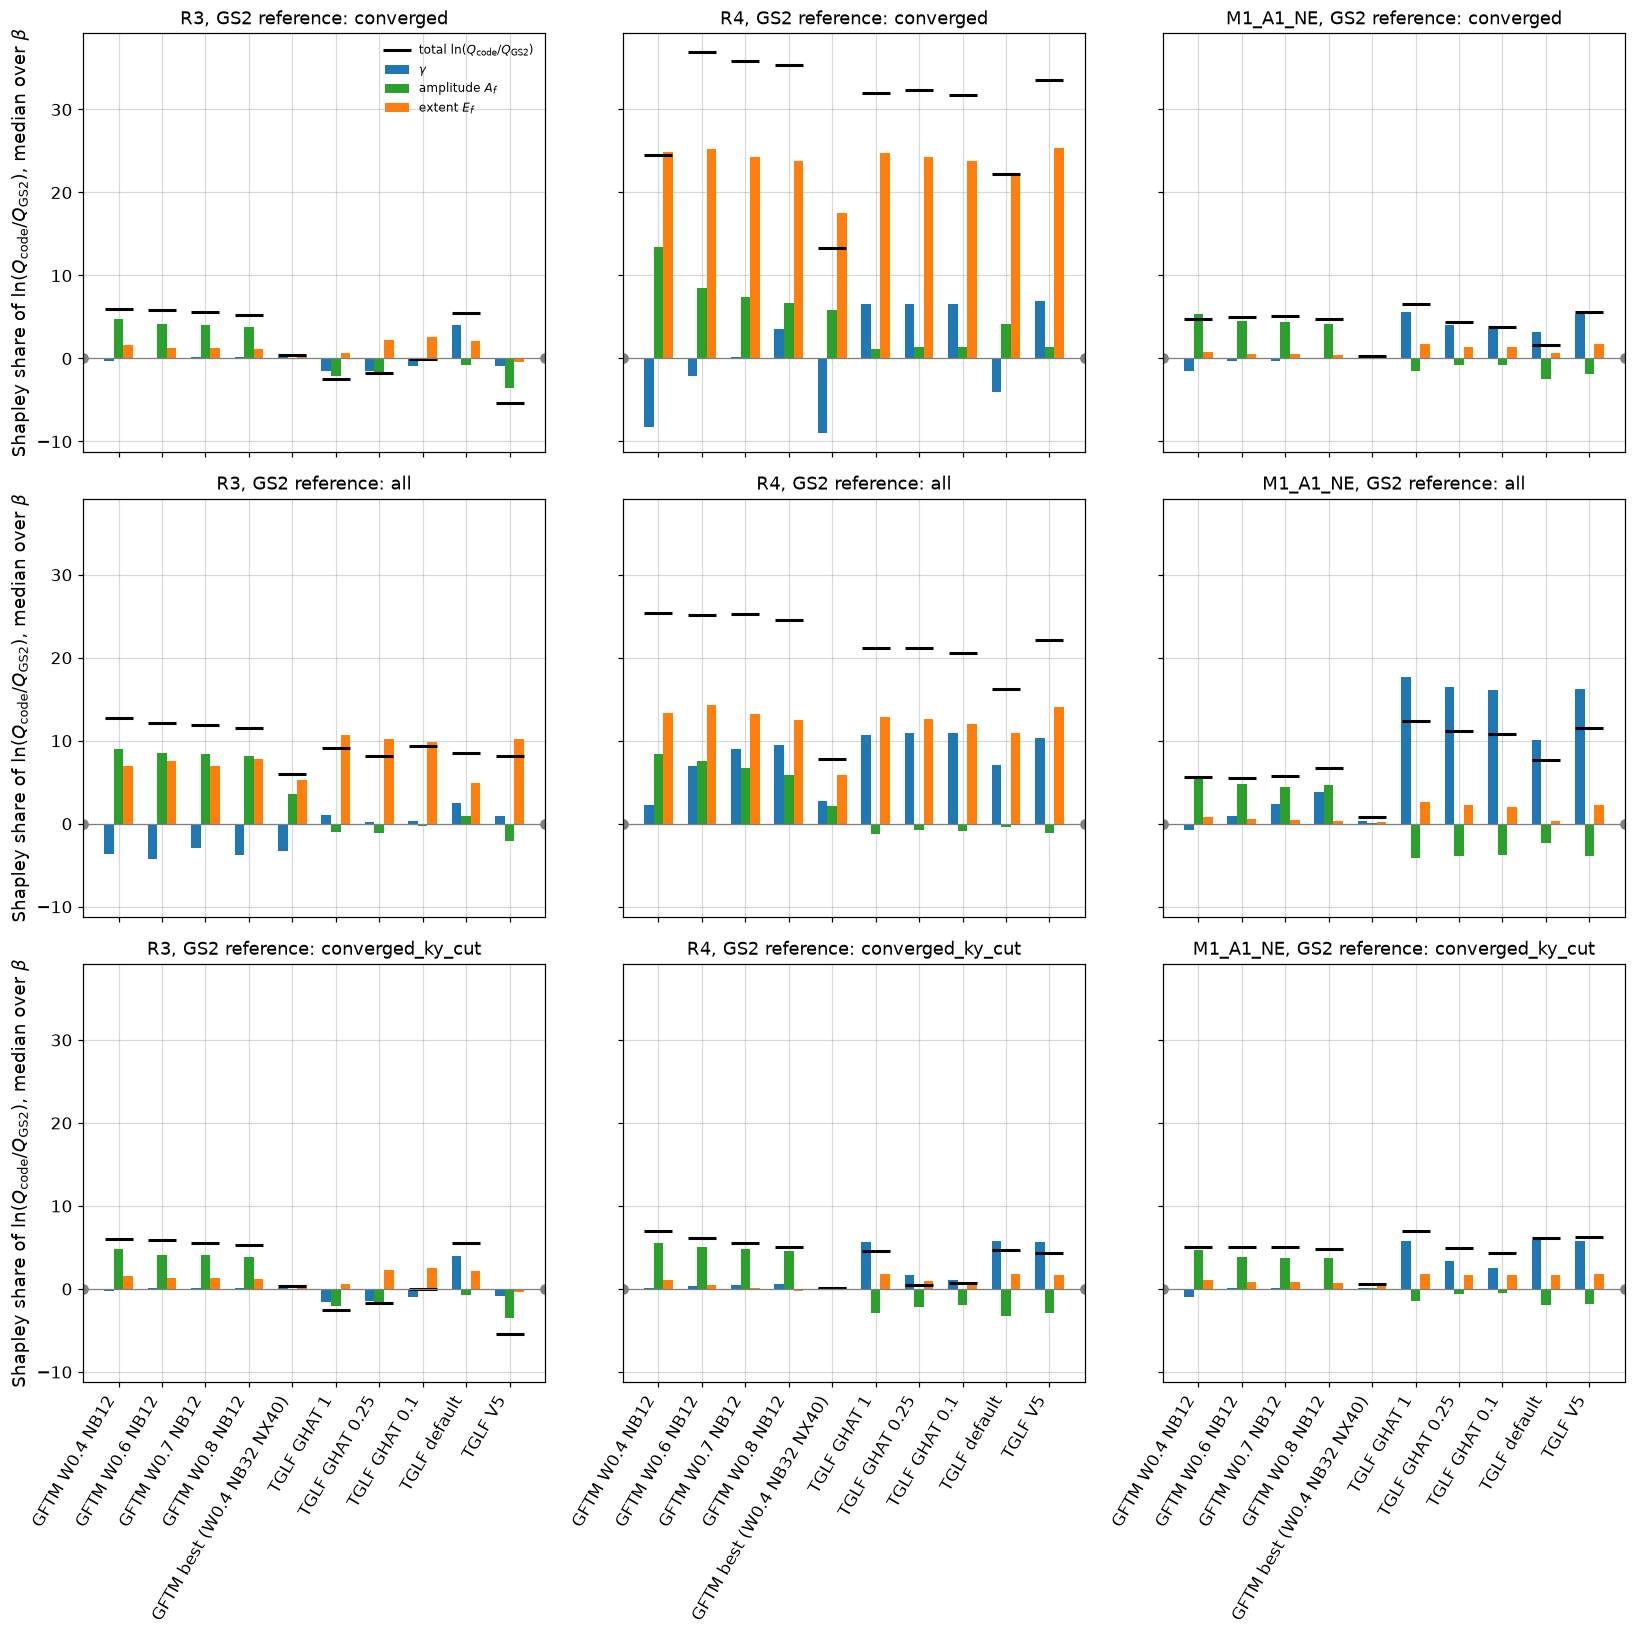

In [6]:
share_columns = [f"share_{p}" for p in players]
colours = {"growth_rate": "C0", "field_amplitude": "C2", "field_extent": "C1"}
fig, axes = plt.subplots(len(references), len(cases), figsize=(5 * len(cases), 5 * len(references)), sharey=True)
for row, reference in enumerate(references):
    for ax, case in zip(axes[row], cases):
        medians = all_shares[(all_shares.reference == reference) & (all_shares.case == case)] \
            .groupby("arm", sort=False)[["log_error", *share_columns]].median().reindex(list(arms))
        positions = np.arange(len(medians))
        width = 0.22
        for offset, player in zip((-width, 0, width), players):
            ax.bar(positions + offset, medians[f"share_{player}"], width, color=colours[player], label=player_label[player])
        ax.plot(positions, medians["log_error"], "k_", markersize=18, mew=2, label=r"total $\ln(Q_{\rm code}/Q_{\rm GS2})$")
        ax.axhline(0, color="grey", lw=0.8)
        ax.set_xticks(positions, medians.index if row == len(references) - 1 else [], rotation=60, ha="right")
        ax.set_title(f"{case}, GS2 reference: {reference}")
    axes[row, 0].set_ylabel(r"Shapley share of $\ln(Q_{\rm code}/Q_{\rm GS2})$, median over $\beta$")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(plot_dir / "plots" / "shapley_shares_by_arm.png", dpi=150)

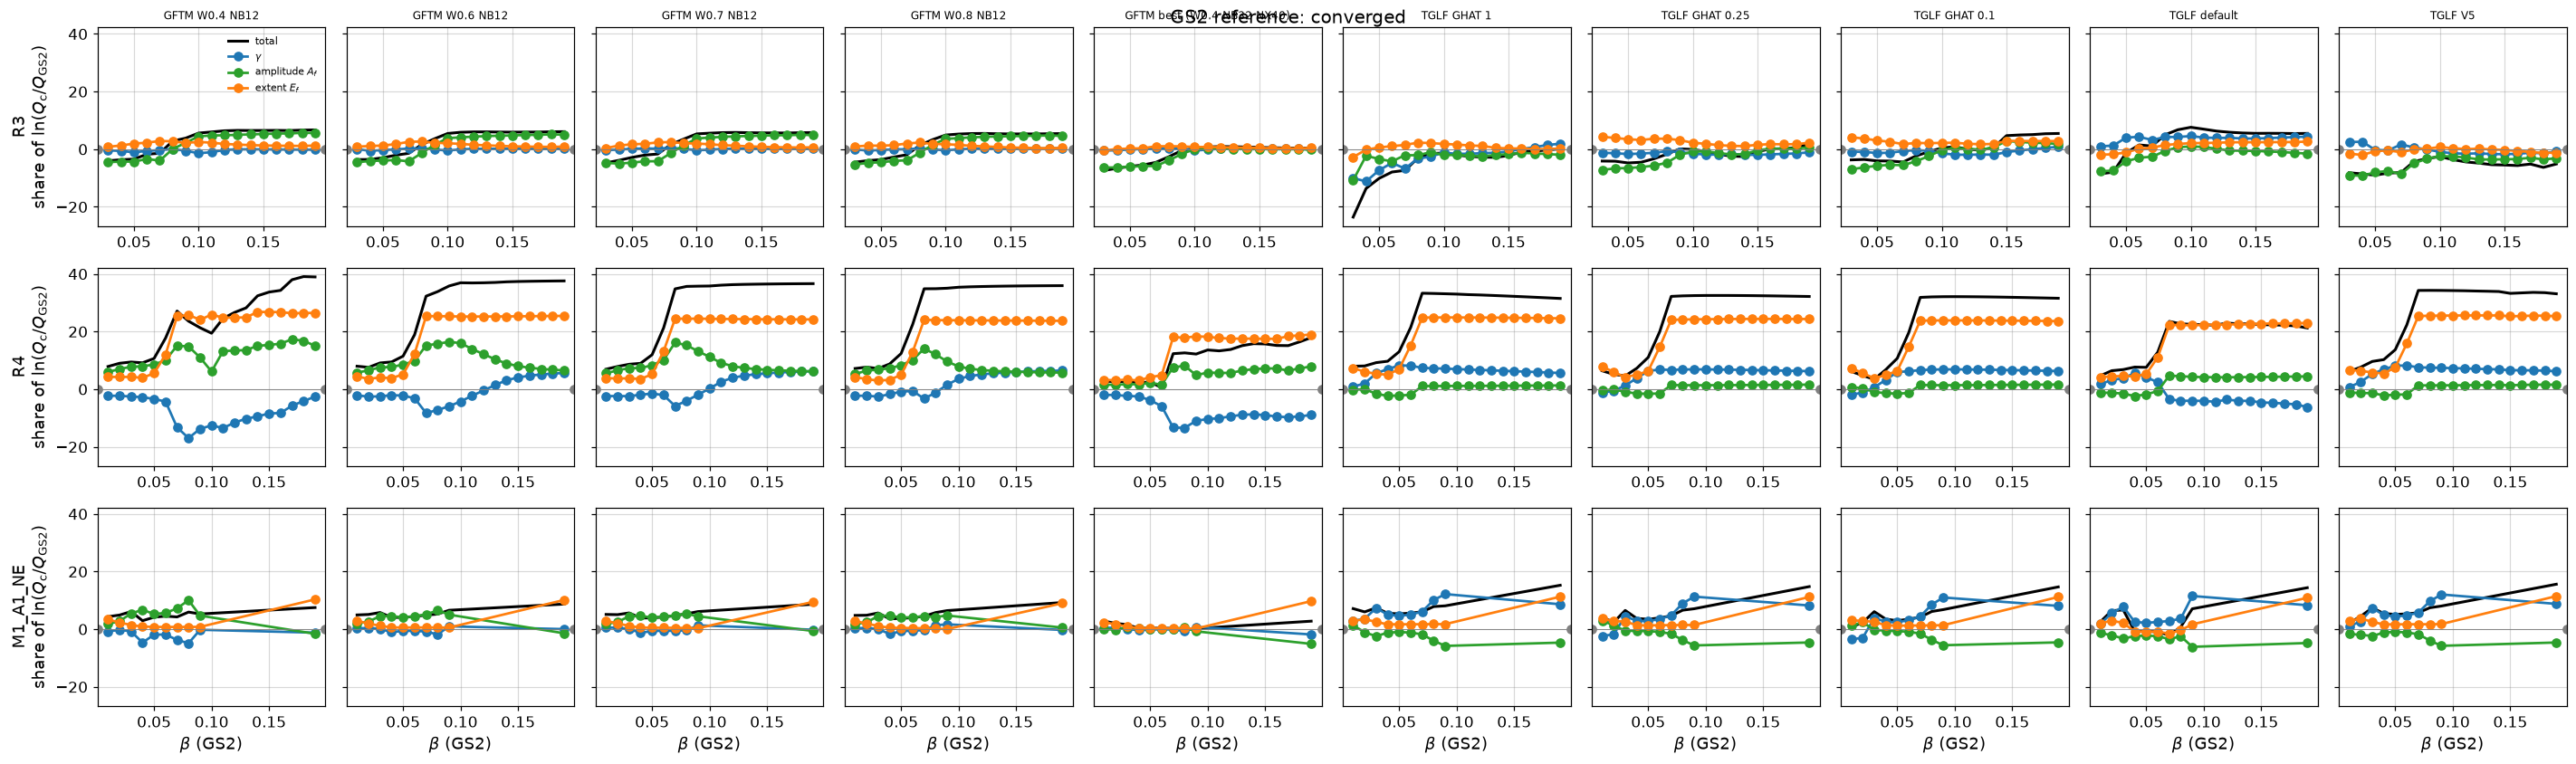

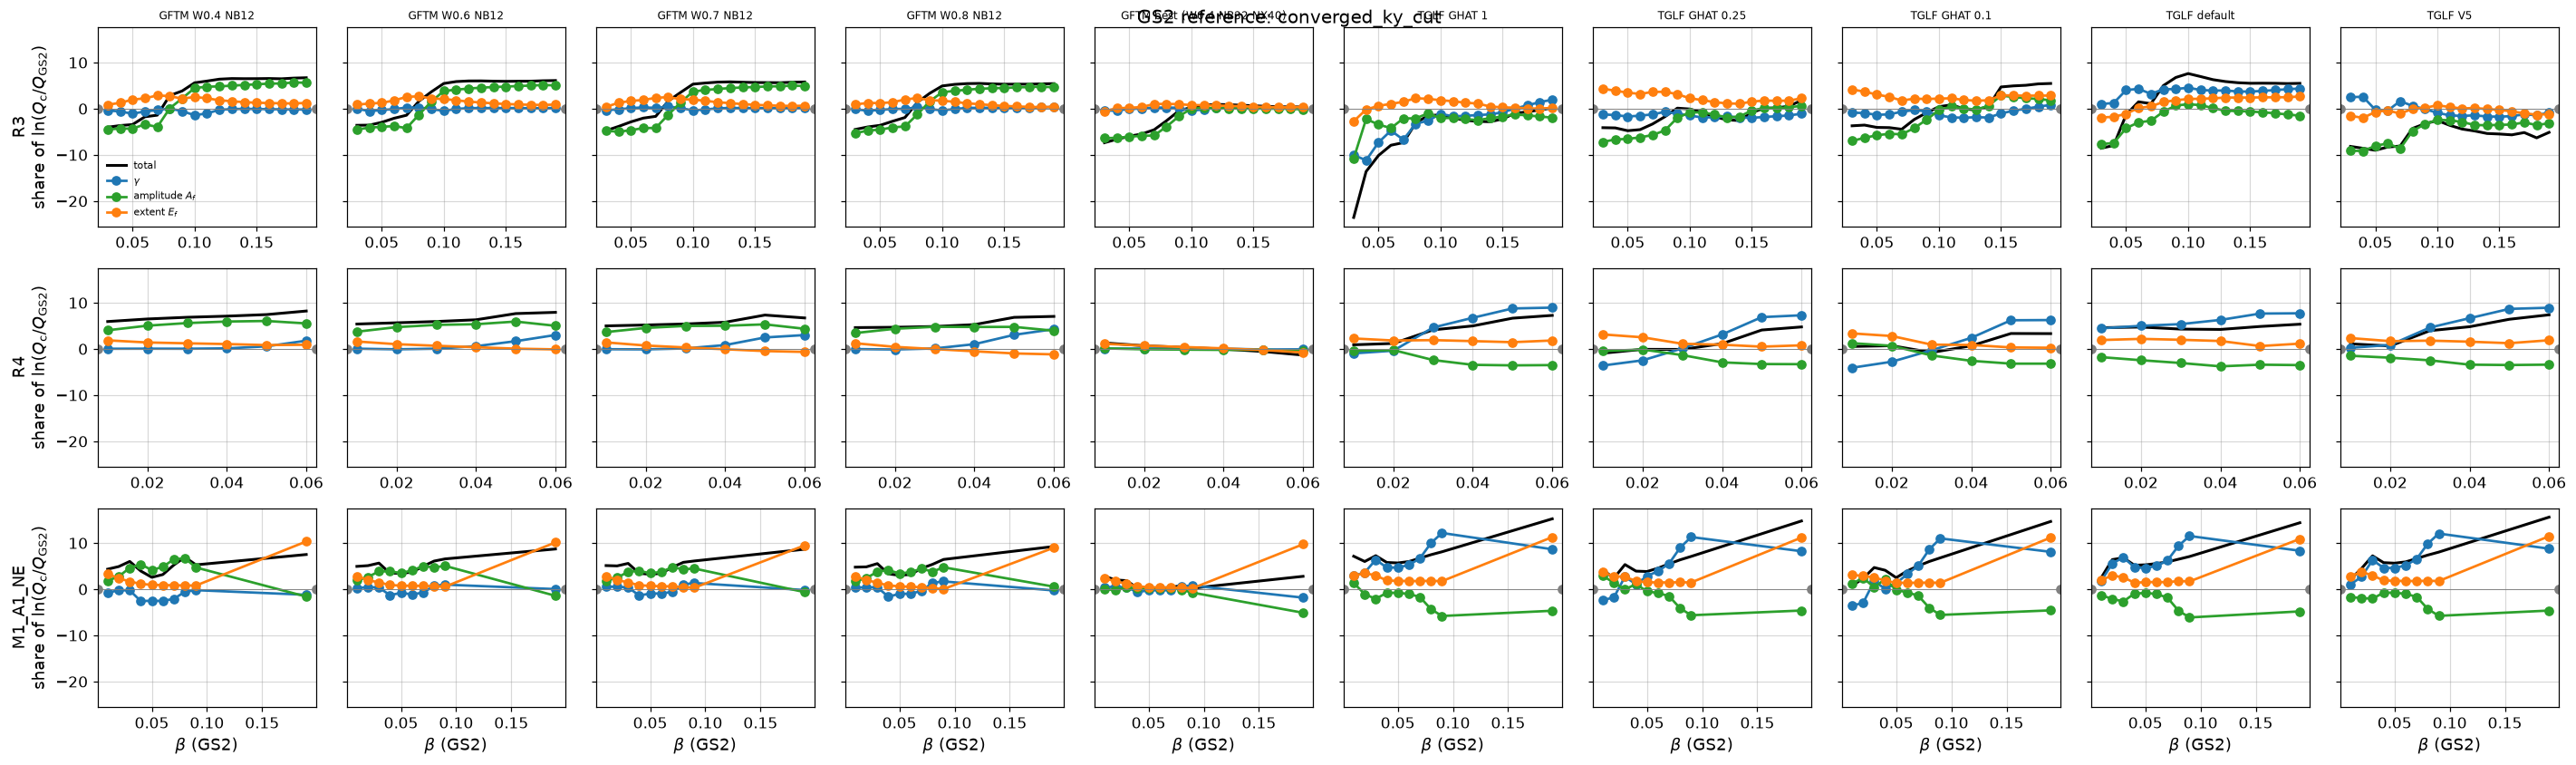

In [7]:
for reference in ["converged", "converged_ky_cut"]:
    fig, axes = plt.subplots(len(cases), len(arms), figsize=(2.6 * len(arms), 2.6 * len(cases)), sharex="row", sharey=True)
    for row, case in enumerate(cases):
        for col, arm in enumerate(arms):
            ax = axes[row, col]
            arm_shares = all_shares[(all_shares.reference == reference) & (all_shares.case == case) & (all_shares.arm == arm)]
            ax.plot(arm_shares.beta_gs2, arm_shares.log_error, "k-", lw=2, label="total")
            for player in players:
                ax.plot(arm_shares.beta_gs2, arm_shares[f"share_{player}"], color=colours[player], label=player_label[player])
            ax.axhline(0, color="grey", lw=0.6)
            if row == 0:
                ax.set_title(arm, fontsize=8)
            if col == 0:
                ax.set_ylabel(f"{case}\n" + r"share of $\ln(Q_{\rm c}/Q_{\rm GS2})$")
            if row == len(cases) - 1:
                ax.set_xlabel(r"$\beta$ (GS2)")
    axes[0, 0].legend(fontsize=7)
    fig.tight_layout()
    fig.suptitle(f"GS2 reference: {reference}")
    fig.savefig(plot_dir / "plots" / f"shapley_shares_vs_beta_{reference}.png", dpi=130)

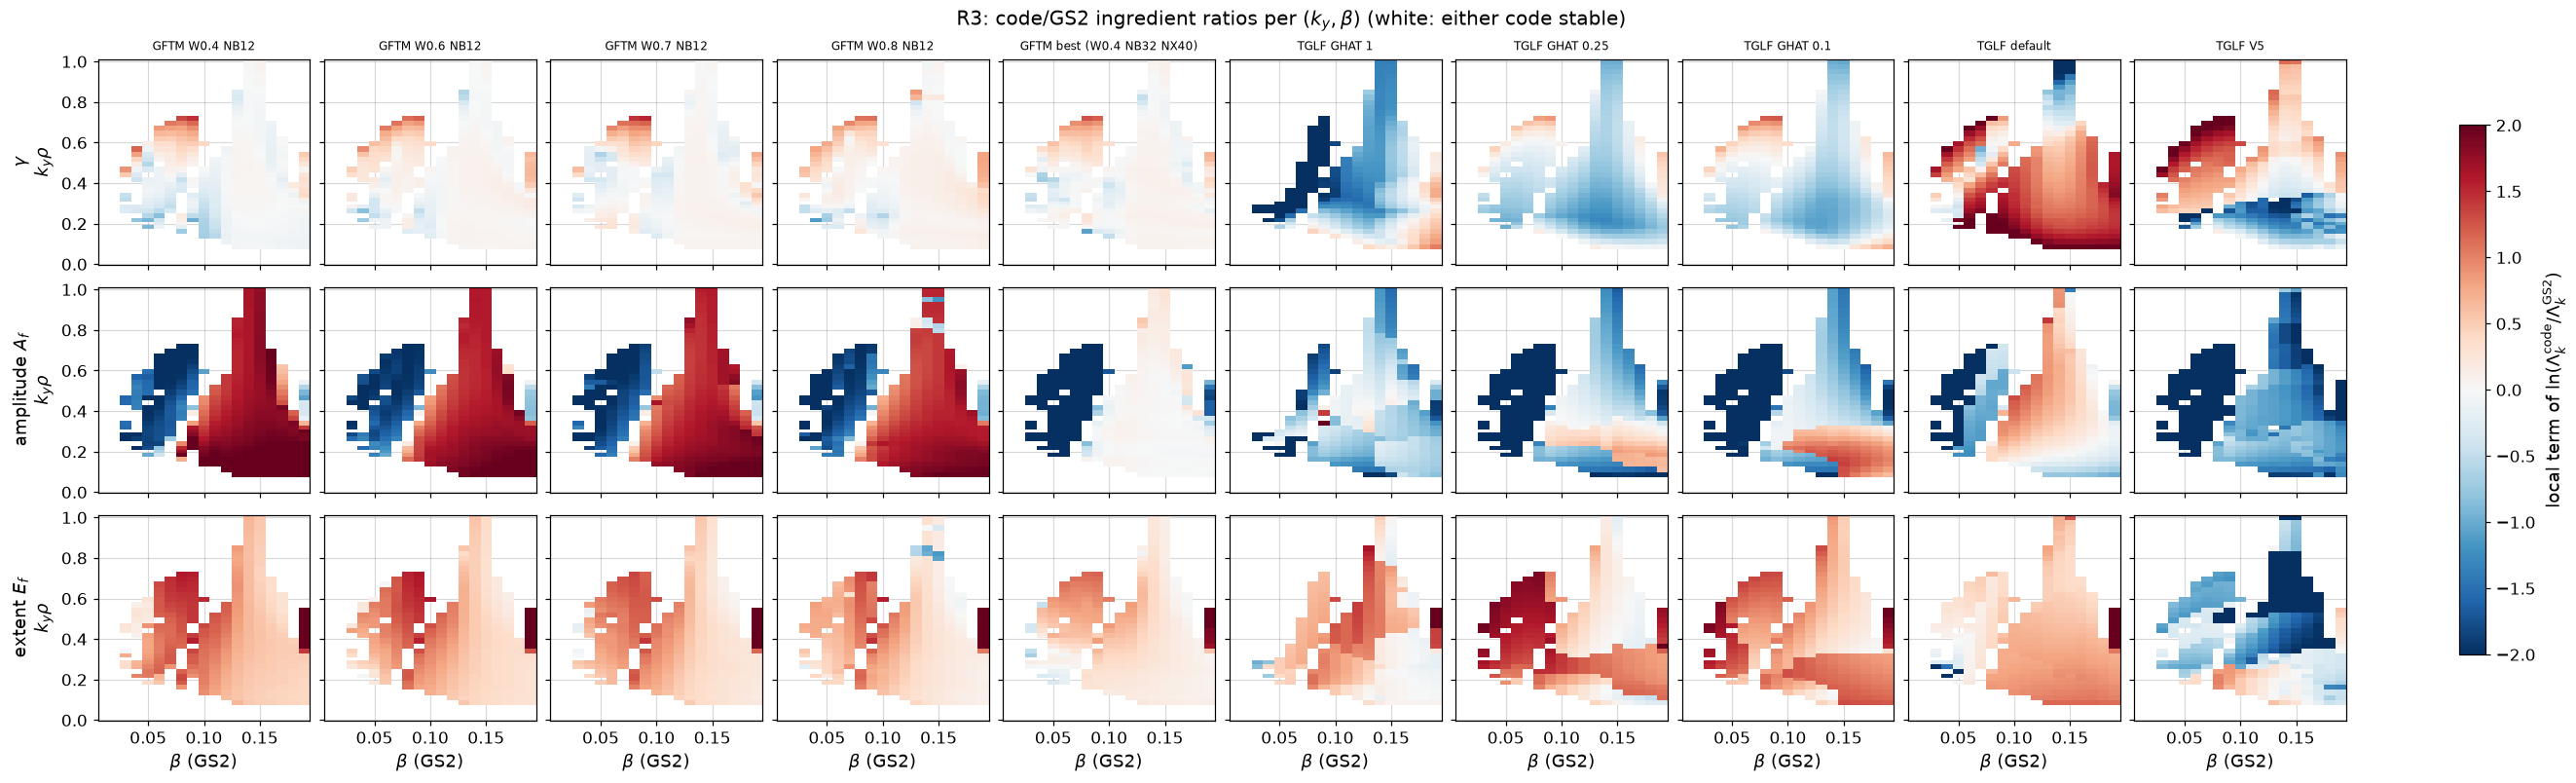

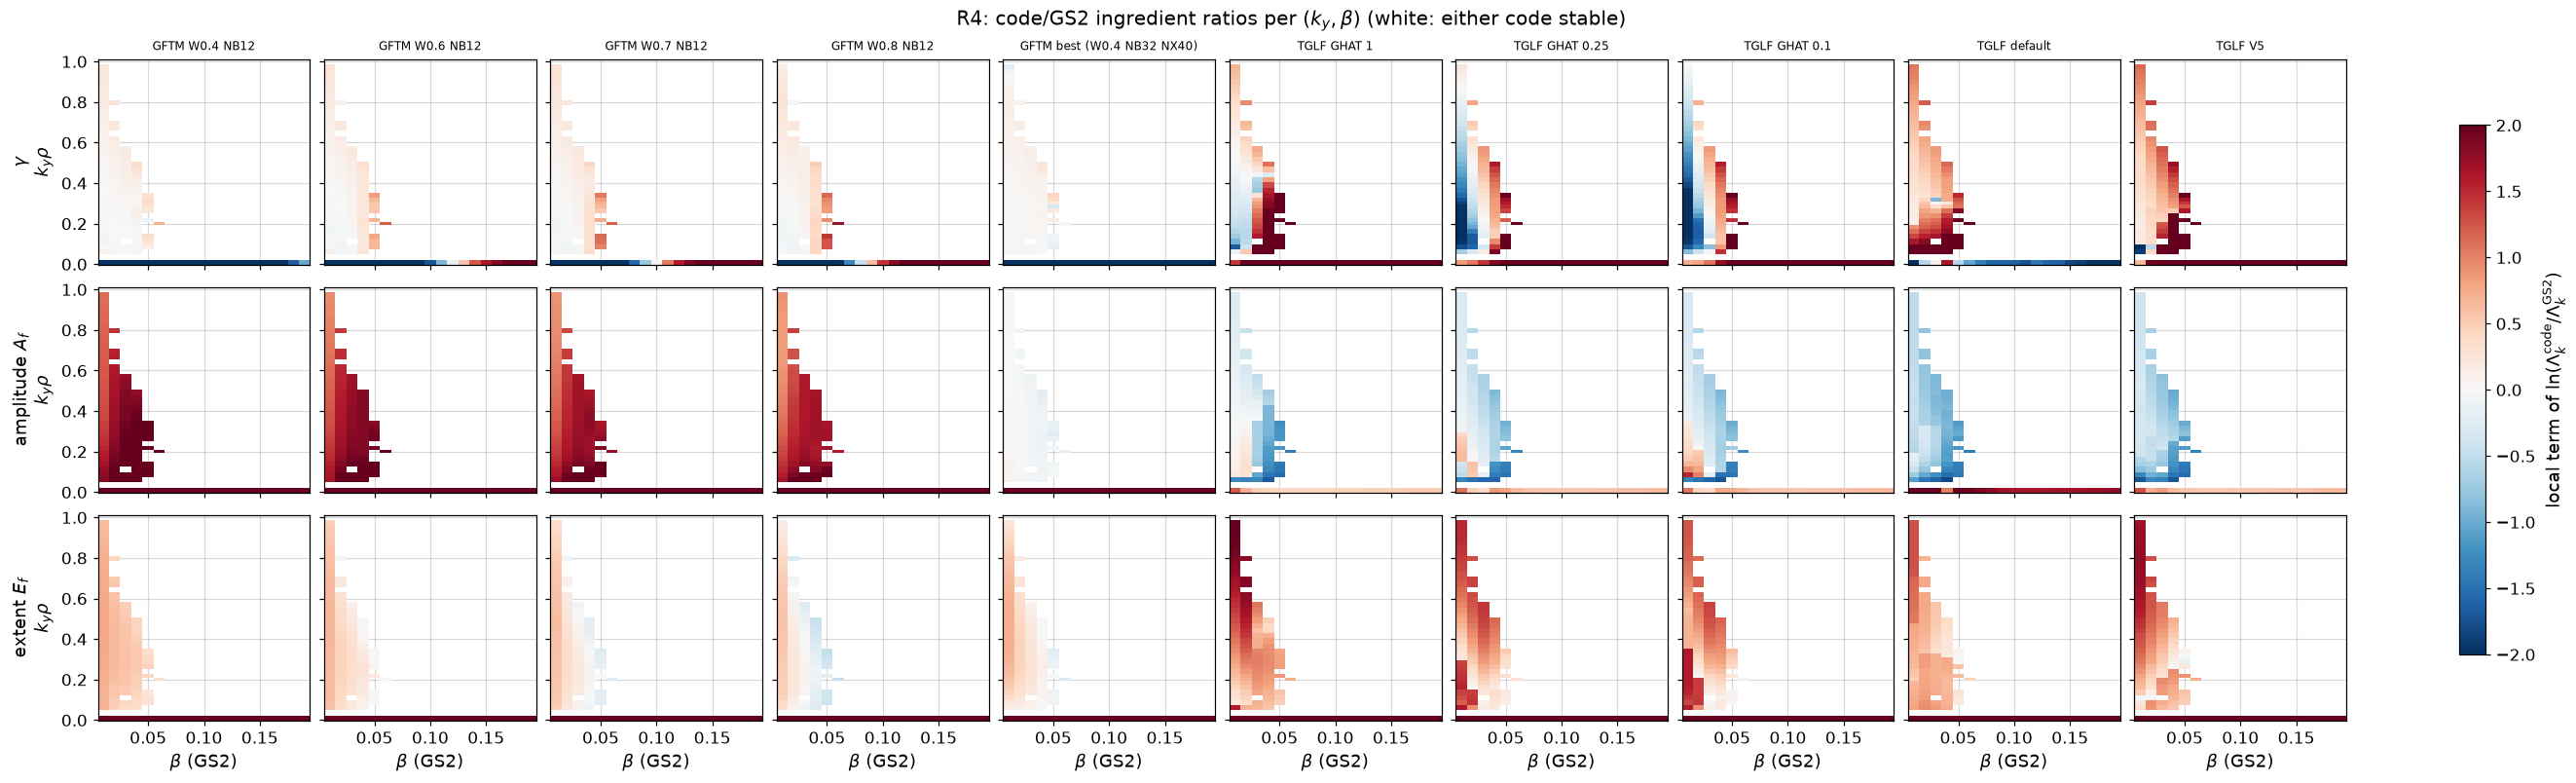

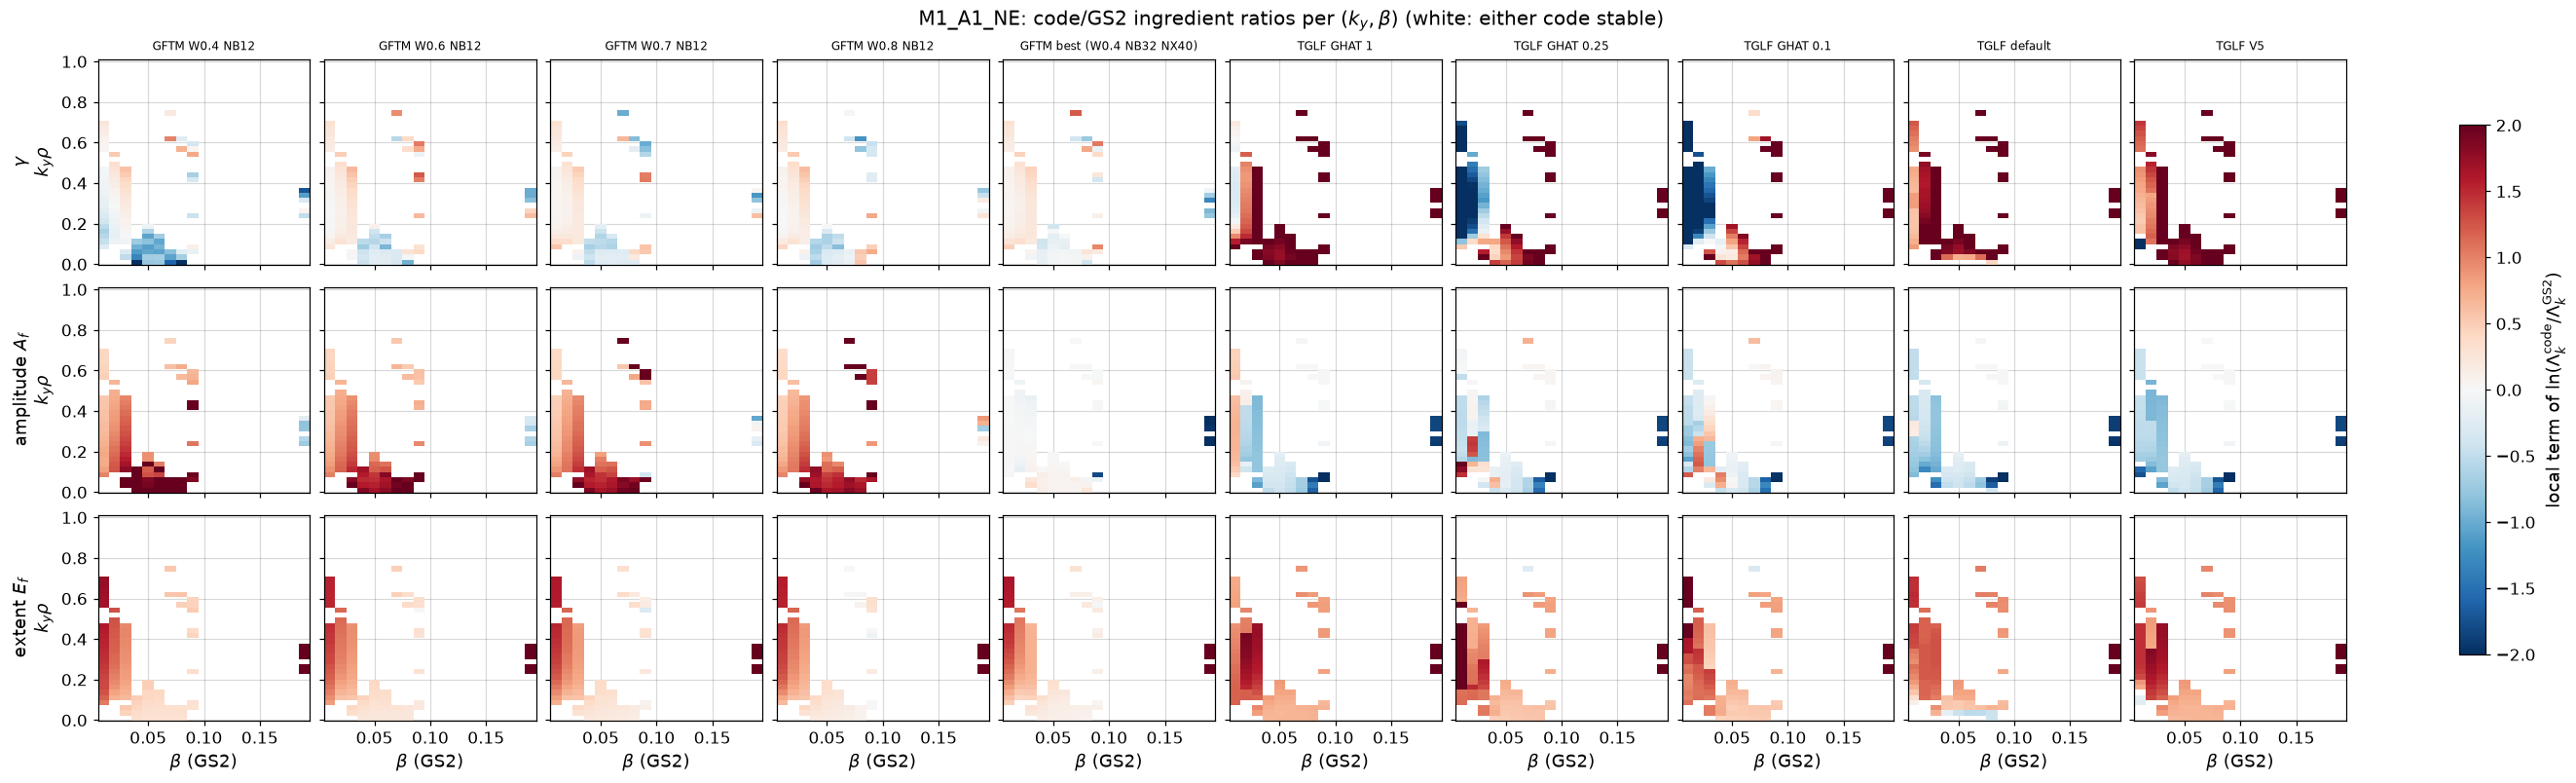

In [8]:
for case in cases:
    fig, axes = plt.subplots(len(players), len(arms), figsize=(2.4 * len(arms), 2.4 * len(players)), sharex=True, sharey=True)
    for col, arm in enumerate(arms):
        for row, player in enumerate(players):
            term = local_maps[(case, arm)][player]
            mesh = axes[row, col].pcolormesh(term.beta, term.ky, term.transpose("ky", "beta"), cmap="RdBu_r",
                                             vmin=-2, vmax=2, shading="nearest")
            if row == 0:
                axes[row, col].set_title(arm, fontsize=8)
            if col == 0:
                axes[row, col].set_ylabel(f"{player_label[player]}\n" + r"$k_y\rho$")
            if row == len(players) - 1:
                axes[row, col].set_xlabel(r"$\beta$ (GS2)")
    fig.colorbar(mesh, ax=axes, label=r"local term of $\ln(\Lambda_k^{\rm code}/\Lambda_k^{\rm GS2})$", shrink=0.8)
    fig.suptitle(f"{case}: code/GS2 ingredient ratios per $(k_y,\\beta)$ (white: either code stable)")
    fig.savefig(plot_dir / "plots" / f"ingredient_ratio_maps_{case}.png", dpi=130)

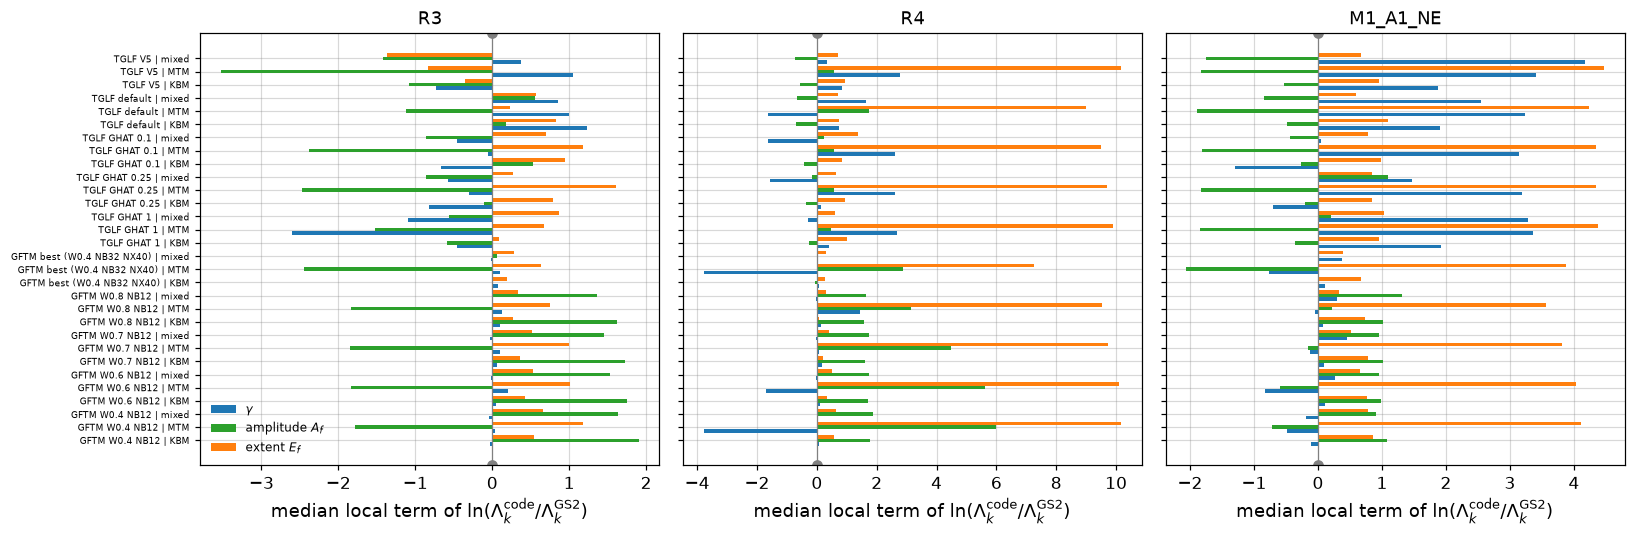

In [9]:
fig, axes = plt.subplots(1, len(cases), figsize=(5 * len(cases), 5), sharey=True)
for ax, case in zip(axes, cases):
    case_split = local_split[(local_split.case == case) & (local_split.n_cells > 0)]
    labels = [f"{arm} | {mode_type}" for arm, mode_type in zip(case_split.arm, case_split.gs2_mode_type)]
    positions = np.arange(len(case_split))
    for offset, player in zip((-0.27, 0, 0.27), players):
        ax.barh(positions + offset, case_split[f"median_{player}"], 0.27, color=colours[player], label=player_label[player])
    ax.set_yticks(positions, labels, fontsize=6)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(case)
    ax.set_xlabel(r"median local term of $\ln(\Lambda_k^{\rm code}/\Lambda_k^{\rm GS2})$")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(plot_dir / "plots" / "local_split_by_mode_type.png", dpi=150)

## Rule dependence: TGLF's own SAT flux against MG(TGLF)

The five TGLF arms re-run in transport mode on the same $\beta$ grid (`TGLF/Runs/scan_beta_sat`, identical
settings plus `USE_TRANSPORT_MODEL=T`, `NKY=12`): TGLF's own SAT flux on its own $k_y$ grid. Its total heat flux is
the sum of pyro's `heat` over field, species and $k_y$ (equal to `out.tglf.gbflux` times one unit factor, 9.0813, at
every $\beta$ and species, checked on R3 GHAT 1). There is no GS2 SAT flux, so the rules are compared on the
**$\beta$ dependence**: $\ln Q(\beta)$ minus its mean over $\beta$, against MG(GS2) the same way. Rule-independent
rankings would order the arms the same under both rules.

TGLF's grid starts at $k_y=0.16$; MG is shown on GS2's full grid and with $k_y\ge0.16$ only. MG here uses
every GS2 run and the unrestricted TGLF arm (reference `all`), as TGLF's SAT uses every $k_y$ it computes.

,case,arm,n_beta,rms_shape_error_mg,rms_shape_error_mg_high_ky,rms_shape_error_sat_vs_mg_gs2,corr_sat_mg_tglf,rank_rms_shape_error_mg,rank_rms_shape_error_mg_high_ky,rank_rms_shape_error_sat_vs_mg_gs2
0,R3,TGLF GHAT 1,19,2.620,5.430,2.311,-0.114,3.0,5.0,1.0
1,R3,TGLF GHAT 0.25,19,3.101,2.293,2.810,-0.673,4.0,2.0,5.0
2,R3,TGLF GHAT 0.1,19,1.471,2.715,2.328,0.758,1.0,3.0,2.0
3,R3,TGLF default,19,6.212,4.750,2.432,0.952,5.0,4.0,3.0
4,R3,TGLF V5,19,2.453,1.818,2.642,-0.392,2.0,1.0,4.0
5,R4,TGLF GHAT 1,11,5.753,5.146,6.604,0.707,1.0,1.0,3.0
6,R4,TGLF GHAT 0.25,11,7.053,5.791,6.140,0.869,3.0,3.0,1.0
7,R4,TGLF GHAT 0.1,11,7.068,5.734,6.243,0.805,4.0,2.0,2.0
8,R4,TGLF default,15,6.323,7.266,7.248,-0.588,2.0,4.0,4.0
9,R4,TGLF V5,15,8.130,8.053,7.249,0.839,5.0,5.0,5.0


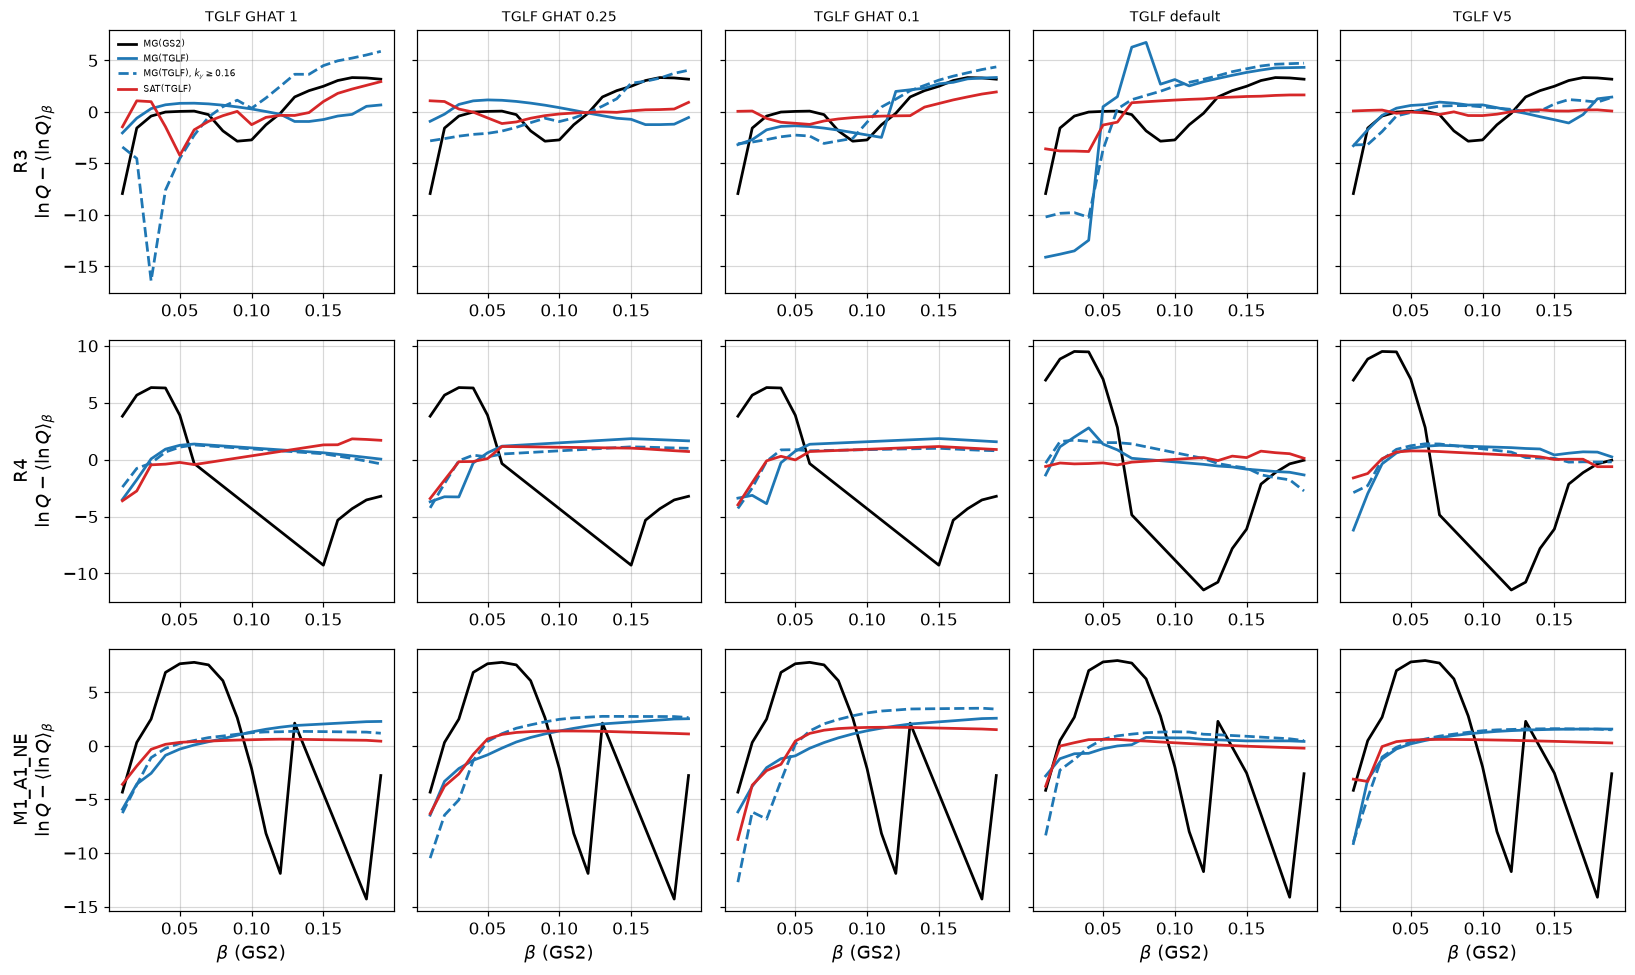

In [10]:
tglf_arms = [arm for arm, (code, _, _) in arms.items() if code == "TGLF"]
sat_scan = {(case, arm): load_scan("TGLF", "scan_beta_sat", case, arms[arm][2]) for case in cases for arm in tglf_arms}

def centred(log_q):
    return log_q - log_q.mean()

rule_rows = []
fig, axes = plt.subplots(len(cases), len(tglf_arms), figsize=(3 * len(tglf_arms), 3 * len(cases)), sharex="row", sharey="row")
for row, case in enumerate(cases):
    gs2_log_q = np.log(gs2_rules[case].mg_flux(gs2_ingredients[(case, "all")])["heat"].pint.dequantify())
    for col, arm in enumerate(tglf_arms):
        sat_heat = sat_scan[(case, arm)].gk_output["heat"].pint.dequantify()
        sat_log_q = np.log(sat_heat.sum(["field", "species", "ky"])).assign_coords(beta=gs2_log_q.beta.values)
        k_min = float(sat_heat.ky.min())
        mg_log_q = log_flux[(case, arm, "all")][frozenset()]
        mg_high_ky_log_q = np.log(gs2_rules[case].mg_flux(arm_ingredients[(case, arm, "all")].sel(ky=slice(k_min, None)))["heat"]
                                  .pint.dequantify())
        gs2_high_ky_log_q = np.log(gs2_rules[case].mg_flux(gs2_ingredients[(case, "all")].sel(ky=slice(k_min, None)))["heat"]
                                   .pint.dequantify())
        valid = np.isfinite(sat_log_q) & np.isfinite(mg_log_q) & np.isfinite(gs2_log_q) \
            & np.isfinite(mg_high_ky_log_q) & np.isfinite(gs2_high_ky_log_q)
        curves = {"MG(GS2)": gs2_log_q, "MG(TGLF)": mg_log_q, "MG(TGLF), $k_y\\geq0.16$": mg_high_ky_log_q,
                  "SAT(TGLF)": sat_log_q}
        ax = axes[row, col]
        for (label, curve), style in zip(curves.items(), ["k-", "C0-", "C0--", "C3-"]):
            ax.plot(curve.beta[valid], centred(curve[valid]), style, label=label)
        if row == 0:
            ax.set_title(arm, fontsize=9)
        if col == 0:
            ax.set_ylabel(f"{case}\n" + r"$\ln Q-\langle\ln Q\rangle_\beta$")
        if row == len(cases) - 1:
            ax.set_xlabel(r"$\beta$ (GS2)")
        rms = lambda curve, reference: float(np.sqrt(((centred(curve[valid]) - centred(reference[valid])) ** 2).mean()))
        rule_rows.append({"case": case, "arm": arm, "n_beta": int(valid.sum()),
                          "rms_shape_error_mg": rms(mg_log_q, gs2_log_q),
                          "rms_shape_error_mg_high_ky": rms(mg_high_ky_log_q, gs2_high_ky_log_q),
                          "rms_shape_error_sat_vs_mg_gs2": rms(sat_log_q, gs2_log_q),
                          "corr_sat_mg_tglf": float(np.corrcoef(sat_log_q[valid], mg_log_q[valid])[0, 1])})
axes[0, 0].legend(fontsize=6)
fig.tight_layout()
fig.savefig(plot_dir / "plots" / "rule_dependence_sat_vs_mg.png", dpi=130)
rule_dependence = pd.DataFrame(rule_rows)
for column in ["rms_shape_error_mg", "rms_shape_error_mg_high_ky", "rms_shape_error_sat_vs_mg_gs2"]:
    rule_dependence[f"rank_{column}"] = rule_dependence.groupby("case")[column].rank()
rule_dependence.round(3)

## Summaries

Small summary tables for the Fusion_PhD README (numbers quoted in prose; not the input of any figure).

In [11]:
summary = all_shares.groupby(["reference", "case", "arm"], sort=False)[["log_error", *share_columns, "interaction"]].median()
summary["n_beta"] = all_shares.groupby(["reference", "case", "arm"], sort=False).size()
summary.round(4).to_csv(plot_dir / "csv" / "shapley_median_by_case_arm.csv")
local_split.round(4).to_csv(plot_dir / "csv" / "local_split_by_mode_type.csv", index=False)
rule_dependence.round(4).to_csv(plot_dir / "csv" / "rule_dependence_sat_vs_mg.csv", index=False)
summary.round(3)

log_error  share_growth_rate  \
reference        case     arm                                            
converged        R3       GFTM W0.4 NB12      5.979             -0.250   
all              R3       GFTM W0.4 NB12     12.694             -3.628   
converged_ky_cut R3       GFTM W0.4 NB12      5.979             -0.250   
converged        R3       GFTM W0.6 NB12      5.868              0.119   
all              R3       GFTM W0.6 NB12     12.183             -4.310   
...                                             ...                ...   
                 M1_A1_NE TGLF default        7.630             10.049   
converged_ky_cut M1_A1_NE TGLF default        6.151              5.899   
converged        M1_A1_NE TGLF V5             5.566              5.345   
all              M1_A1_NE TGLF V5            11.570             16.268   
converged_ky_cut M1_A1_NE TGLF V5             6.271              5.721   

                                          share_field_amplitude  \
reference        case     arm                                     
converged        R3       GFTM W0.4 NB12                  4.762   
all              R3       GFTM W0.4 NB12                  8.958   
converged_ky_cut R3       GFTM W0.4 NB12                  4.762   
converged        R3       GFTM W0.6 NB12                  4.112   
all              R3       GFTM W0.6 NB12                  8.535   
...                                                         ...   
                 M1_A1_NE TGLF default                   -2.359   
converged_ky_cut M1_A1_NE TGLF default                   -1.982   
converged        M1_A1_NE TGLF V5                        -1.841   
all              M1_A1_NE TGLF V5                        -3.862   
converged_ky_cut M1_A1_NE TGLF V5                        -1.815   

                                          share_field_extent  interaction  \
reference        case     arm                                               
converged        R3       GFTM W0.4 NB12               1.610       -2.121   
all              R3       GFTM W0.4 NB12               6.993        0.053   
converged_ky_cut R3       GFTM W0.4 NB12               1.610       -2.121   
converged        R3       GFTM W0.6 NB12               1.262       -2.137   
all              R3       GFTM W0.6 NB12               7.544       -0.023   
...                                                      ...          ...   
                 M1_A1_NE TGLF default                 0.379        0.362   
converged_ky_cut M1_A1_NE TGLF default                 1.722        0.396   
converged        M1_A1_NE TGLF V5                      1.732       -0.554   
all              M1_A1_NE TGLF V5                      2.271       -0.161   
converged_ky_cut M1_A1_NE TGLF V5                      1.854       -0.686   

                                          n_beta  
reference        case     arm                     
converged        R3       GFTM W0.4 NB12      17  
all              R3       GFTM W0.4 NB12      19  
converged_ky_cut R3       GFTM W0.4 NB12      17  
converged        R3       GFTM W0.6 NB12      17  
all              R3       GFTM W0.6 NB12      19  
...                                          ...  
                 M1_A1_NE TGLF default        18  
converged_ky_cut M1_A1_NE TGLF default        10  
converged        M1_A1_NE TGLF V5             10  
all              M1_A1_NE TGLF V5             18  
converged_ky_cut M1_A1_NE TGLF V5             10  

[90 rows x 6 columns]